# Error Analysis — CARLA SGCC

Analisis **dimana dan mengapa** model CARLA salah pada dataset SGCC (electricity theft detection).

Urutan analisis:
1. Setup & konfigurasi  
2. Inferensi per-consumer + per-window  
3. Score distribution (normal vs theft)  
4. ROC & PR curves  
5. Confusion matrix  
6. Tabel FP / FN per consumer  
7. Time series — FP consumers (normal diprediksi pencuri)  
8. Time series — FN consumers (pencuri yang lolos)  
9. Per-window score heatmap  
10. Ringkasan

In [1]:
import sys, os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score,
    confusion_matrix, f1_score
)

def _find_carla_root():
    candidates = [Path(os.path.abspath('')), Path(os.path.abspath('..'))]
    for c in candidates:
        if (c / 'carla_pretext.py').exists():
            return c
    p = Path(os.path.abspath(''))
    for _ in range(5):
        if (p / 'carla_pretext.py').exists():
            return p
        p = p.parent
    raise RuntimeError('CARLA root tidak ditemukan.')

BASE_DIR = _find_carla_root()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))
os.chdir(BASE_DIR)

from utils.config import create_config
from utils.common_config import get_model, get_val_transformations1, inject_sub_anomaly
from utils.collate import collate_custom
from utils.dataset_channels import get_sgcc_train_files, get_sgcc_test_files
from data.SGCC import SGCC

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device  : {device}')
print(f'BASE_DIR: {BASE_DIR}')

Device  : cpu
BASE_DIR: d:\CARLA


## 1. Konfigurasi

In [2]:
# ============================================================
# KONFIGURASI — sesuaikan di sini
# ============================================================
AGG   = 'mean'   # 'mean' | 'max' | 'pct'
SEED  = None     # None = default | 0, 1, 2, ... untuk multiseed

CONFIG_ENV = str(BASE_DIR / 'configs' / 'env.yml')
CONFIG_CLS = str(BASE_DIR / 'configs' / 'classification' / 'carla_classification_sgcc.yml')

p = create_config(CONFIG_ENV, CONFIG_CLS, 'All')

_atype   = (p.get('anomaly_kwargs') or {}).get('type', 'subseq') or 'subseq'
_seed_tag = '' if SEED is None else f'_s{SEED}'
TAG       = f'{_atype}_{AGG}{_seed_tag}'
MODEL_PATH = p['classification_model']

print(f'Model path : {MODEL_PATH}')
print(f'Aggregation: {AGG}')
print(f'Anomaly    : {_atype}')
print(f'TAG        : {TAG}')
assert Path(MODEL_PATH).exists(), f'Model belum ada: {MODEL_PATH}. Jalankan run_sgcc.py dahulu.'

Model path : results/sgcc\All/classification\model.pth.tar
Aggregation: mean
Anomaly    : subseq
TAG        : subseq_mean


## 2. Load Model & Inferensi Per-Consumer + Per-Window

In [3]:
model = get_model(p)
model = torch.nn.DataParallel(model)
ckpt  = torch.load(MODEL_PATH, map_location='cpu', weights_only=False)
model.module.load_state_dict(ckpt['model'])
model.to(device).eval()

val_transform = get_val_transformations1(p)
sanomaly      = inject_sub_anomaly(p)

@torch.no_grad()
def get_logits(model, ts):
    if ts.ndim == 3:
        b, w, h = ts.shape
    else:
        b, w = ts.shape; h = 1
    out = model(ts.view(b, h, w))
    return out[0] if isinstance(out, (list, tuple)) else out

# Normal label dari pool consumer training
train_files = get_sgcc_train_files()
print(f'Pooling {len(train_files)} consumer training untuk majority vote ...')
train_ds = None
for ii, fname in enumerate(train_files):
    ds = SGCC(fname, train=True, transform=val_transform, sanomaly=sanomaly)
    train_ds = ds if train_ds is None else (train_ds.concat_ds(ds) or train_ds)
    if (ii+1) % 5000 == 0:
        print(f'  {ii+1}/{len(train_files)} ...')

train_dl = torch.utils.data.DataLoader(
    train_ds, batch_size=p['batch_size'], shuffle=False,
    num_workers=p['num_workers'], collate_fn=collate_custom, drop_last=False)

all_preds = []
with torch.no_grad():
    for batch in train_dl:
        ts = batch['ts_org'].to(device)
        preds = torch.argmax(get_logits(model, ts), dim=1).cpu().numpy()
        all_preds.append(preds)
all_preds = np.concatenate(all_preds)
values, counts = np.unique(all_preds, return_counts=True)
normal_label = int(values[np.argmax(counts)])
print(f'Normal label (majority): {normal_label}  ({dict(zip(values.tolist(), counts.tolist()))})')

Pooling 18993 consumer training untuk majority vote ...
  5000/18993 ...
  10000/18993 ...
  15000/18993 ...
Normal label (majority): 0  ({0: 303888})


In [4]:
def aggregate_scores(scores, method='mean'):
    if method == 'mean':  return float(np.mean(scores))
    if method == 'max':   return float(np.max(scores))
    if method == 'pct':   return float(np.mean(scores >= 0.5))
    return float(np.mean(scores))

# Inferensi per consumer
test_files  = get_sgcc_test_files()
rows        = []
window_data = {}

with torch.no_grad():
    for fname in test_files:
        ds = SGCC(fname, train=False, transform=val_transform, sanomaly=sanomaly)
        dl = torch.utils.data.DataLoader(
            ds, batch_size=p['batch_size'], shuffle=False,
            num_workers=p['num_workers'], collate_fn=collate_custom, drop_last=False)

        win_scores, win_labels, raw_wins = [], [], []
        for batch in dl:
            ts     = batch['ts_org'].to(device)
            logits = get_logits(model, ts)
            probs  = F.softmax(logits, dim=1).cpu().numpy()
            scores = 1.0 - probs[:, normal_label]
            win_scores.extend(scores.tolist())
            win_labels.extend(batch['target'].cpu().numpy().tolist())
            raw_wins.append(batch['ts_org'].cpu().numpy())

        win_scores = np.array(win_scores)
        true_label = int(win_labels[0])
        file_score = aggregate_scores(win_scores, AGG)

        rows.append({
            'fname': fname, 'true_label': true_label, 'score': file_score,
            'n_windows': len(win_scores),
            'score_min': float(win_scores.min()), 'score_max': float(win_scores.max()),
            'score_std': float(win_scores.std()),
        })
        window_data[fname] = {
            'win_scores': win_scores,
            'raw_windows': np.concatenate(raw_wins, axis=0),
            'true_label': true_label,
        }

df = pd.DataFrame(rows)
print(f'Total consumer test: {len(df)}  (normal: {(df.true_label==0).sum()}, theft: {(df.true_label==1).sum()})')
df.head(10)

Total consumer test: 3435  (normal: 2374, theft: 1061)


,fname,true_label,score,n_windows,score_min,score_max,score_std
0,33F8B51384EC8ADA9E5330FD5345F112.npy,0,0.537874,16,0.537874,0.537874,0.0
1,46EC5445CCF01251084B4B893210A825.npy,0,0.537874,16,0.537874,0.537874,0.0
2,585EB252527F7325D97AFA5EC91EEAB9.npy,0,0.537874,16,0.537874,0.537874,0.0
3,C621F11E8B69DC21B3114A63734CB184.npy,0,0.537874,16,0.537874,0.537874,0.0
4,F0A3840274EC6110309A44F54EF8FA33.npy,0,0.537874,16,0.537874,0.537874,0.0
5,7DEFDE2F8CF6D0FA3B90DAC42DAA5644.npy,0,0.537874,16,0.537874,0.537874,0.0
6,C339B3A0E9D61BFDBA55C6F4DE66231F.npy,0,0.537874,16,0.537874,0.537874,0.0
7,C1D98587D84CD0D0A7EB4BABDEC71477.npy,0,0.537874,16,0.537874,0.537874,0.0
8,07217A820F644ADDB1FD73FB20B56897.npy,0,0.537874,16,0.537874,0.537874,0.0
9,0BB854E6D8E47B5F6280754F47DE9695.npy,0,0.537874,16,0.537874,0.537874,0.0


In [5]:
# Hitung threshold & label prediksi
file_scores = df['score'].values
file_labels = df['true_label'].values

prec_curve, rec_curve, thr_pr = precision_recall_curve(file_labels, file_scores)
f1_curve = np.where(
    (prec_curve + rec_curve) > 0,
    2 * prec_curve * rec_curve / (prec_curve + rec_curve), 0.0)
best_idx  = int(np.argmax(f1_curve[:-1]))
THRESHOLD = float(thr_pr[best_idx])

df['pred_label'] = (df['score'] >= THRESHOLD).astype(int)
df['result'] = df.apply(lambda r:
    'TP' if r.true_label==1 and r.pred_label==1 else
    'TN' if r.true_label==0 and r.pred_label==0 else
    'FP' if r.true_label==0 and r.pred_label==1 else 'FN', axis=1)

auroc = roc_auc_score(file_labels, file_scores) if len(np.unique(file_labels)) > 1 else float('nan')
aupr  = average_precision_score(file_labels, file_scores)
f1    = f1_score(file_labels, df['pred_label'].values, zero_division=0)

print(f'Threshold : {THRESHOLD:.4f}')
print(f'AUROC     : {auroc:.4f}')
print(f'AUPR      : {aupr:.4f}')
print(f'F1 (theft): {f1:.4f}')
print(f"\nDistribusi: {df['result'].value_counts().to_dict()}")

Threshold : 0.5379
AUROC     : 0.5000
AUPR      : 0.3089
F1 (theft): 0.4720

Distribusi: {'FP': 2374, 'TP': 1061}


## 3. Score Distribution

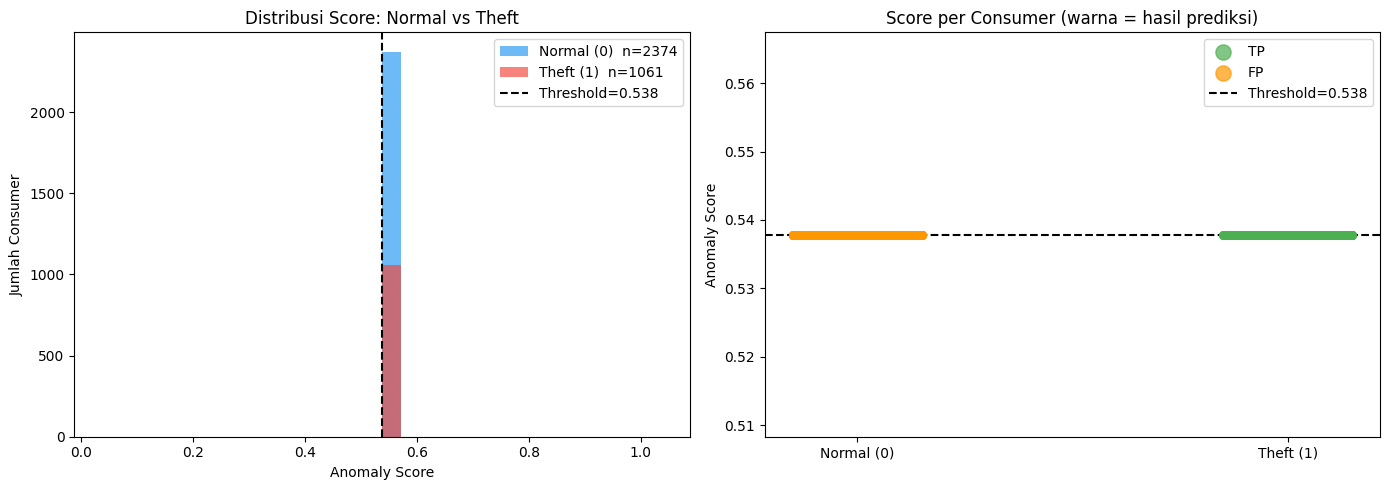

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for lbl, col, name in [(0, '#2196F3', 'Normal (0)'), (1, '#F44336', 'Theft (1)')]:
    sub = df[df.true_label == lbl]['score'].values
    ax.hist(sub, bins=30, alpha=0.65, color=col, label=f'{name}  n={len(sub)}')
ax.axvline(THRESHOLD, color='black', linestyle='--', linewidth=1.5,
           label=f'Threshold={THRESHOLD:.3f}')
ax.set_xlabel('Anomaly Score')
ax.set_ylabel('Jumlah Consumer')
ax.set_title('Distribusi Score: Normal vs Theft')
ax.legend()

rng = np.random.default_rng(42)
ax2 = axes[1]
result_colors = {'TP': '#4CAF50', 'TN': '#2196F3', 'FP': '#FF9800', 'FN': '#F44336'}
for res, col in result_colors.items():
    sub = df[df.result == res]
    if len(sub) == 0: continue
    x_base = 0 if sub.true_label.iloc[0] == 0 else 1
    x = rng.uniform(-0.15, 0.15, len(sub)) + x_base
    ax2.scatter(x, sub['score'].values, color=col, alpha=0.7, s=30, label=res, zorder=3)
ax2.axhline(THRESHOLD, color='black', linestyle='--', linewidth=1.5,
            label=f'Threshold={THRESHOLD:.3f}')
ax2.set_xticks([0, 1])
ax2.set_xticklabels(['Normal (0)', 'Theft (1)'])
ax2.set_ylabel('Anomaly Score')
ax2.set_title('Score per Consumer (warna = hasil prediksi)')
ax2.legend(markerscale=2)

plt.tight_layout()
out_dir = BASE_DIR / 'results' / 'figures'
out_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(out_dir / f'error_sgcc_score_dist_{TAG}.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. ROC & PR Curves

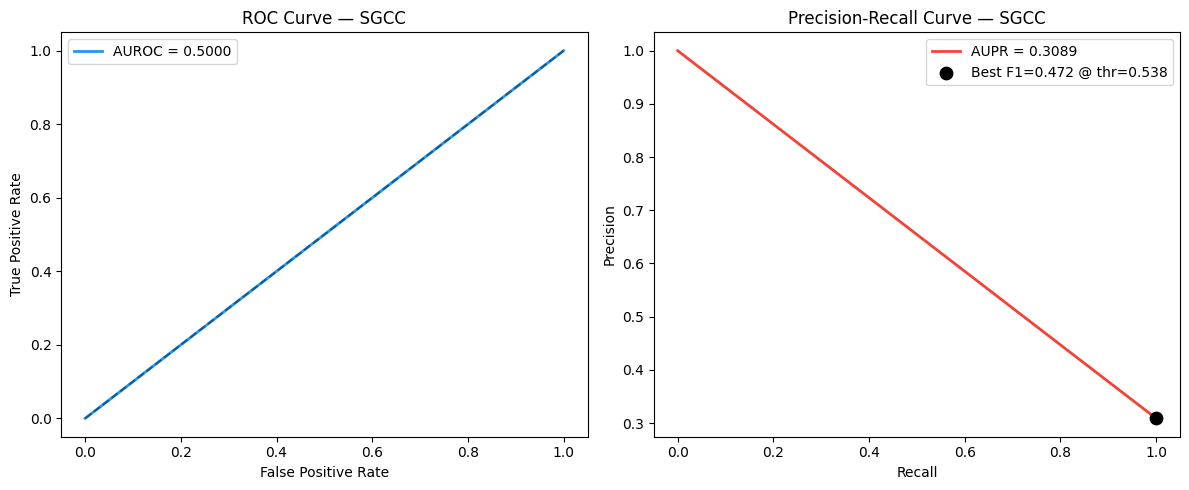

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
if not np.isnan(auroc):
    fpr, tpr, thr_roc = roc_curve(file_labels, file_scores)
    ax.plot(fpr, tpr, color='#2196F3', lw=2, label=f'AUROC = {auroc:.4f}')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve — SGCC')
ax.legend()

ax2 = axes[1]
ax2.plot(rec_curve, prec_curve, color='#F44336', lw=2, label=f'AUPR = {aupr:.4f}')
ax2.scatter([rec_curve[best_idx]], [prec_curve[best_idx]], color='black', zorder=5, s=80,
            label=f'Best F1={f1:.3f} @ thr={THRESHOLD:.3f}')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curve — SGCC')
ax2.legend()

plt.tight_layout()
plt.savefig(out_dir / f'error_sgcc_roc_pr_{TAG}.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Confusion Matrix

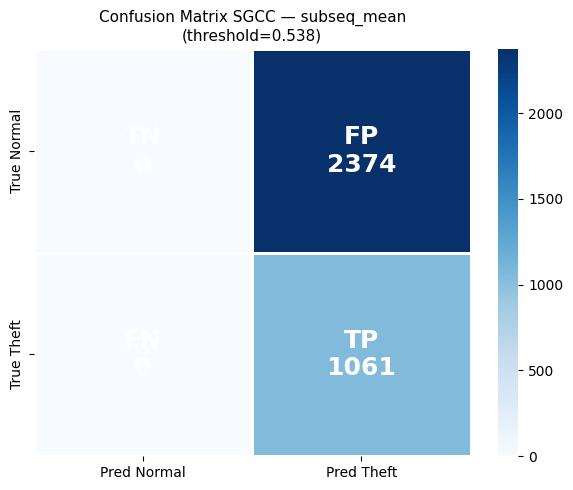

TN=0  FP=2374  FN=0  TP=1061


In [8]:
cm = confusion_matrix(file_labels, df['pred_label'].values, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=False, cmap='Blues', ax=ax,
            xticklabels=['Pred Normal', 'Pred Theft'],
            yticklabels=['True Normal', 'True Theft'],
            linewidths=1, linecolor='white')
cell_labels = [[f'TN\n{tn}', f'FP\n{fp}'], [f'FN\n{fn}', f'TP\n{tp}']]
for i in range(2):
    for j in range(2):
        ax.text(j + 0.5, i + 0.5, cell_labels[i][j],
                ha='center', va='center', fontsize=18, fontweight='bold', color='white')
ax.set_title(f'Confusion Matrix SGCC — {TAG}\n(threshold={THRESHOLD:.3f})', fontsize=11)
plt.tight_layout()
plt.savefig(out_dir / f'error_sgcc_confusion_{TAG}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')

## 6. Tabel FP / FN Per Consumer

In [9]:
cols_show = ['fname', 'true_label', 'pred_label', 'score',
             'score_min', 'score_max', 'score_std', 'n_windows', 'result']

fp_df = df[df.result == 'FP'][cols_show].sort_values('score', ascending=False)
fn_df = df[df.result == 'FN'][cols_show].sort_values('score', ascending=True)

print(f'=== FALSE POSITIVE ({len(fp_df)} consumer normal diprediksi theft) ===')
display(fp_df)

print(f'\n=== FALSE NEGATIVE ({len(fn_df)} pencuri yang lolos) ===')
display(fn_df)

def highlight_result(row):
    color_map = {'TP': 'background-color: #c8e6c9', 'TN': 'background-color: #bbdefb',
                 'FP': 'background-color: #ffe0b2', 'FN': 'background-color: #ffcdd2'}
    return [color_map.get(row.result, '')] * len(row)

print('\n=== SEMUA CONSUMER (diurutkan berdasarkan score) ===')
display(df[cols_show].sort_values('score', ascending=False)
        .style.apply(highlight_result, axis=1)
        .format({'score': '{:.4f}', 'score_min': '{:.4f}',
                 'score_max': '{:.4f}', 'score_std': '{:.4f}'}))

=== FALSE POSITIVE (2374 consumer normal diprediksi theft) ===


,fname,true_label,pred_label,score,score_min,score_max,score_std,n_windows,result
0,33F8B51384EC8ADA9E5330FD5345F112.npy,0,1,0.537874,0.537874,0.537874,0.0,16,FP
1,46EC5445CCF01251084B4B893210A825.npy,0,1,0.537874,0.537874,0.537874,0.0,16,FP
2,585EB252527F7325D97AFA5EC91EEAB9.npy,0,1,0.537874,0.537874,0.537874,0.0,16,FP
3,C621F11E8B69DC21B3114A63734CB184.npy,0,1,0.537874,0.537874,0.537874,0.0,16,FP
4,F0A3840274EC6110309A44F54EF8FA33.npy,0,1,0.537874,0.537874,0.537874,0.0,16,FP
...,...,...,...,...,...,...,...,...,...
2369,944163514410B399A07006EAA53FC5B4.npy,0,1,0.537874,0.537874,0.537874,0.0,16,FP
2370,96A901601FAF648876EAA505C2624CF0.npy,0,1,0.537874,0.537874,0.537874,0.0,16,FP
2371,47A3D489CED81DB3D0332E95FD4C3596.npy,0,1,0.537874,0.537874,0.537874,0.0,16,FP
2372,9D02C9439C02D19181C2A95A71BBD8D7.npy,0,1,0.537874,0.537874,0.537874,0.0,16,FP



=== FALSE NEGATIVE (0 pencuri yang lolos) ===


,fname,true_label,pred_label,score,score_min,score_max,score_std,n_windows,result



=== SEMUA CONSUMER (diurutkan berdasarkan score) ===


## 7. Time Series — False Positive Consumers

FP consumers: 2374


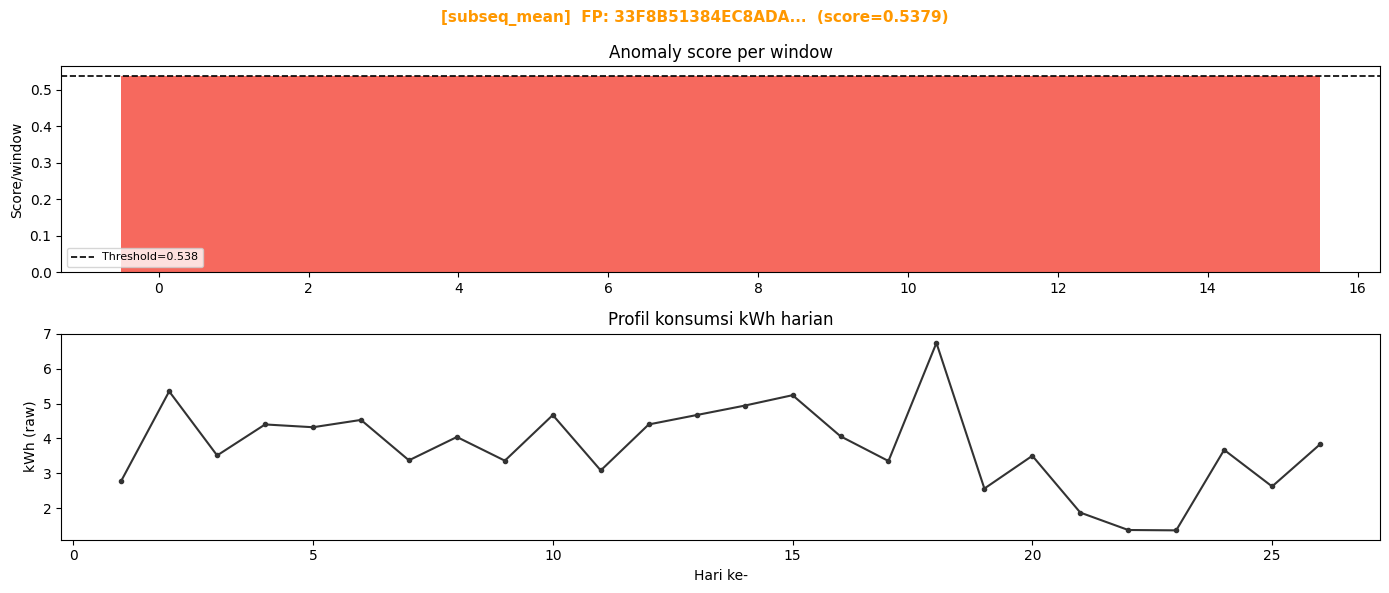

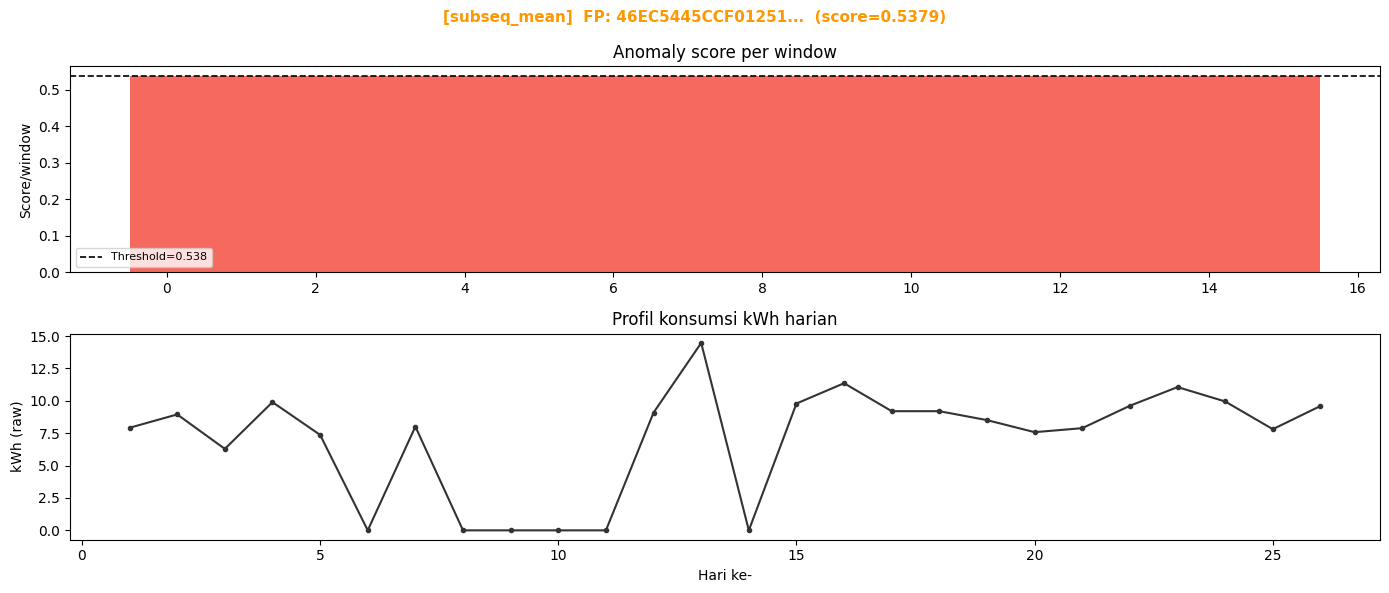

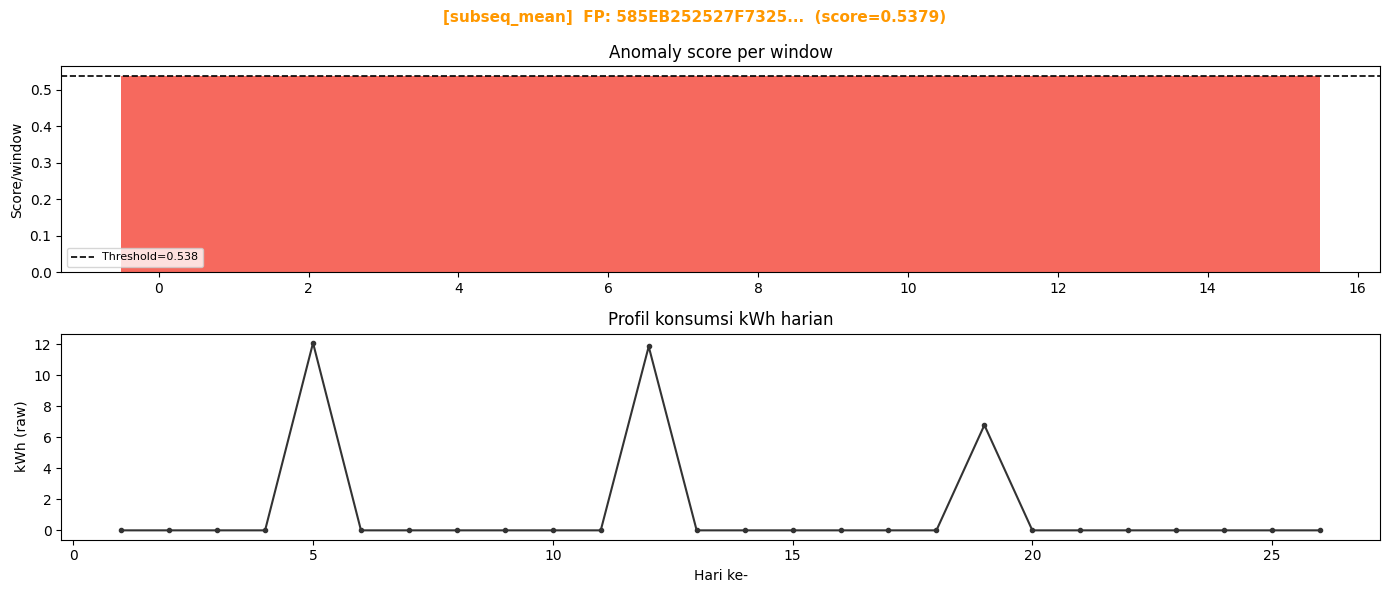

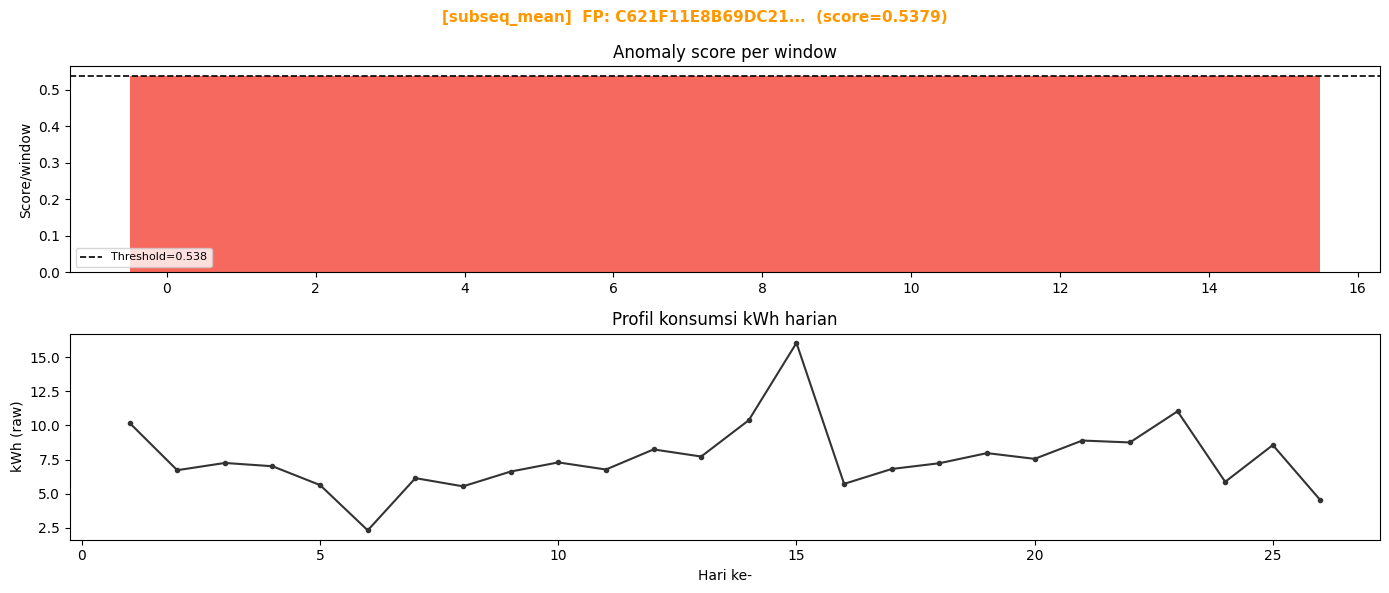

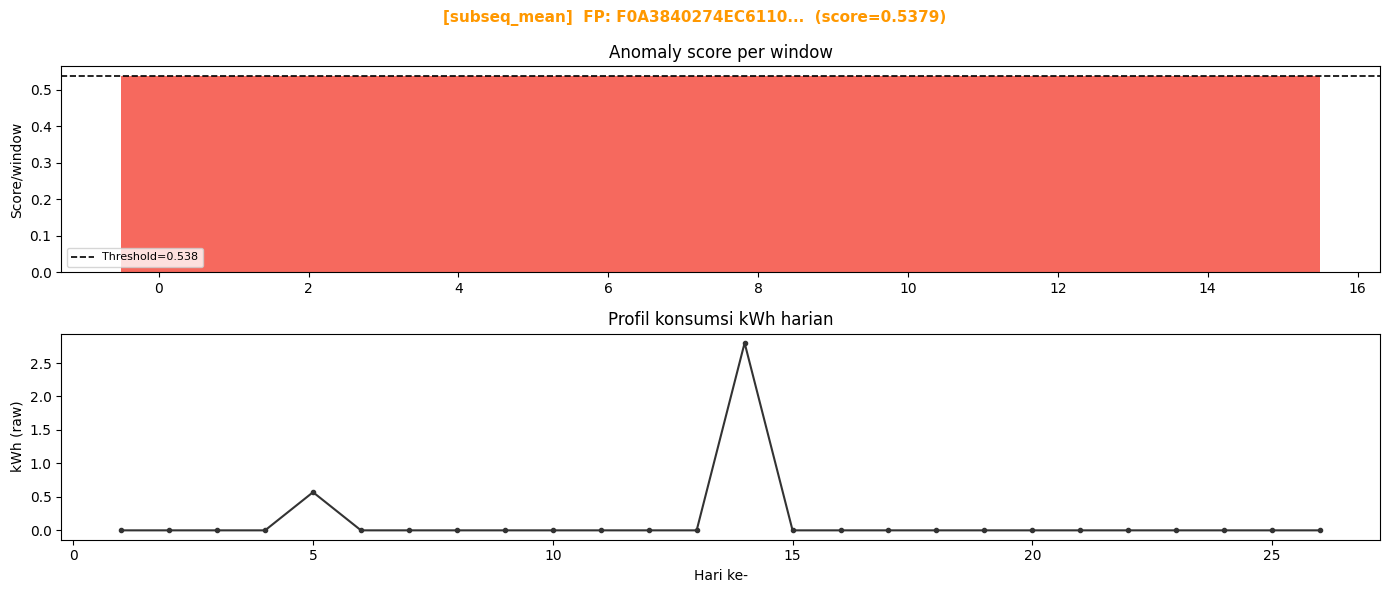

In [10]:
def plot_consumer_timeseries(fname, result_label, max_features=1):
    data       = window_data[fname]
    win_scores = data['win_scores']
    file_score = df.loc[df.fname == fname, 'score'].values[0]

    # Load raw .npy dari processed
    npy_path = BASE_DIR / 'datasets' / 'SGCC' / 'processed' / 'data' / fname
    full_ts  = np.load(str(npy_path)) if npy_path.exists() else data['raw_windows'][0]
    n_feat   = min(full_ts.shape[1] if full_ts.ndim > 1 else 1, max_features)

    title_color = {'FP': '#FF9800', 'FN': '#F44336', 'TP': '#4CAF50', 'TN': '#2196F3'}\
                  .get(result_label, 'black')
    # Truncate CONS_NO for display
    short_id = fname.replace('.npy', '')[:16] + '...'

    fig, axes = plt.subplots(n_feat + 1, 1, figsize=(14, 3 * (n_feat + 1)), sharex=False)
    if n_feat == 0:
        axes = [axes]
    fig.suptitle(f'[{TAG}]  {result_label}: {short_id}  (score={file_score:.4f})',
                 fontsize=11, fontweight='bold', color=title_color)

    ax0 = axes[0]
    bar_colors = ['#F44336' if s >= THRESHOLD else '#2196F3' for s in win_scores]
    ax0.bar(range(len(win_scores)), win_scores, color=bar_colors, width=1.0, alpha=0.8)
    ax0.axhline(THRESHOLD, color='black', linestyle='--', linewidth=1.2,
                label=f'Threshold={THRESHOLD:.3f}')
    ax0.set_ylabel('Score/window')
    ax0.set_title('Anomaly score per window')
    ax0.legend(fontsize=8)

    for i in range(n_feat):
        ax = axes[i + 1]
        col = full_ts[:, i] if full_ts.ndim > 1 else full_ts
        ax.plot(range(1, len(col)+1), col, color='#333333', linewidth=1.5, marker='o', markersize=3)
        ax.set_ylabel('kWh (raw)')
        ax.set_xlabel('Hari ke-')
        ax.set_title('Profil konsumsi kWh harian')

    plt.tight_layout()
    safe = fname.replace('.npy', '')[:20]
    plt.savefig(out_dir / f'error_sgcc_{result_label}_{TAG}_{safe}.png', dpi=120, bbox_inches='tight')
    plt.show()
    plt.close()


fp_files = df[df.result == 'FP']['fname'].tolist()
if fp_files:
    print(f'FP consumers: {len(fp_files)}')
    for fname in fp_files[:5]:
        plot_consumer_timeseries(fname, 'FP')
else:
    print('Tidak ada False Positive.')

## 8. Time Series — False Negative Consumers (pencuri yang lolos)

In [11]:
fn_files = df[df.result == 'FN']['fname'].tolist()
if fn_files:
    print(f'FN consumers: {len(fn_files)}')
    for fname in fn_files[:5]:
        plot_consumer_timeseries(fname, 'FN')
else:
    print('Tidak ada False Negative — semua pencuri terdeteksi!')

Tidak ada False Negative — semua pencuri terdeteksi!


## 9. Per-Window Score Heatmap

Consumer : 33F8B51384EC8ADA9E5330FD5345F112...
Label    : 0  |  Pred: 1  |  Result: FP
Score    : 0.5379  (min=0.5379, max=0.5379)


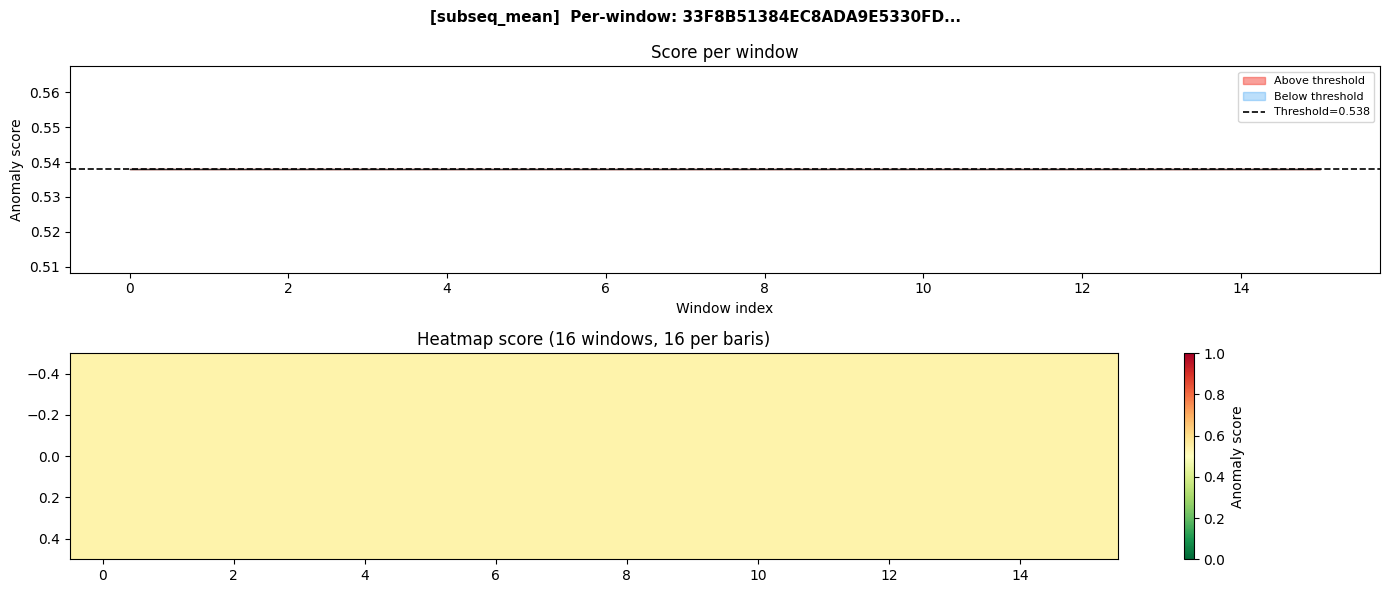

In [12]:
candidates   = fn_files + fp_files
fname_target = candidates[0] if candidates else df['fname'].iloc[0]

row_target = df[df.fname == fname_target].iloc[0]
print(f'Consumer : {fname_target[:32]}...')
print(f'Label    : {row_target.true_label}  |  Pred: {row_target.pred_label}  |  Result: {row_target.result}')
print(f'Score    : {row_target.score:.4f}  (min={row_target.score_min:.4f}, max={row_target.score_max:.4f})')

wscores = window_data[fname_target]['win_scores']
N_win   = len(wscores)

fig, axes = plt.subplots(2, 1, figsize=(14, 6))

ax = axes[0]
ax.plot(wscores, color='#333333', linewidth=1)
ax.fill_between(range(N_win), wscores, THRESHOLD,
                where=(wscores >= THRESHOLD), color='#F44336', alpha=0.5, label='Above threshold')
ax.fill_between(range(N_win), wscores, THRESHOLD,
                where=(wscores < THRESHOLD),  color='#2196F3', alpha=0.3, label='Below threshold')
ax.axhline(THRESHOLD, color='black', linestyle='--', linewidth=1.2,
           label=f'Threshold={THRESHOLD:.3f}')
ax.set_xlabel('Window index')
ax.set_ylabel('Anomaly score')
ax.set_title('Score per window')
ax.legend(fontsize=8)
fig.suptitle(f'[{TAG}]  Per-window: {fname_target[:24]}...', fontsize=11, fontweight='bold')

ax2 = axes[1]
n_cols = min(N_win, 20)  # SGCC: T=26, W=7 → max 19 windows
n_rows = int(np.ceil(N_win / n_cols))
padded = np.pad(wscores, (0, n_rows * n_cols - N_win), constant_values=np.nan)
heatmap_data = padded.reshape(n_rows, n_cols)

im = ax2.imshow(heatmap_data, aspect='auto', cmap='RdYlGn_r', vmin=0, vmax=1)
plt.colorbar(im, ax=ax2, label='Anomaly score')
ax2.set_title(f'Heatmap score ({N_win} windows, {n_cols} per baris)')

plt.tight_layout()
safe = fname_target.replace('.npy', '')[:20]
plt.savefig(out_dir / f'error_sgcc_heatmap_{TAG}_{safe}.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Ringkasan Error Analysis

In [13]:
print('=' * 58)
print(f'  ERROR ANALYSIS — SGCC  [{TAG}]')
print('=' * 58)
print(f'  Total consumer test : {len(df)}')
print(f'  Normal              : {(df.true_label==0).sum()}')
print(f'  Theft               : {(df.true_label==1).sum()}')
print(f'  Threshold           : {THRESHOLD:.4f}  (auto: max F1 pada PR curve)')
print(f'  AUROC               : {auroc:.4f}')
print(f'  AUPR                : {aupr:.4f}')
print(f'  F1 (theft)          : {f1:.4f}')
print(f'  TP={tp}  TN={tn}  FP={fp}  FN={fn}')
print('-' * 58)

if fp > 0:
    print(f'  FP ({fp}) — normal diprediksi theft:')
    for _, row in fp_df.head(5).iterrows():
        short = row.fname[:24] + '...'
        print(f'    {short}  score={row.score:.4f}  std={row.score_std:.4f}')

if fn > 0:
    print(f'  FN ({fn}) — pencuri yang lolos:')
    for _, row in fn_df.head(5).iterrows():
        short = row.fname[:24] + '...'
        print(f'    {short}  score={row.score:.4f}  std={row.score_std:.4f}')

print('=' * 58)
print('Interpretasi FN : pola konsumsi pencuri mirip normal — score rendah/konsisten.')
print('Interpretasi FP : konsumen normal dengan variasi pola tidak biasa.')
print(f'\nFigure tersimpan di: results/figures/error_sgcc_*_{TAG}*.png')

  ERROR ANALYSIS — SGCC  [subseq_mean]
  Total consumer test : 3435
  Normal              : 2374
  Theft               : 1061
  Threshold           : 0.5379  (auto: max F1 pada PR curve)
  AUROC               : 0.5000
  AUPR                : 0.3089
  F1 (theft)          : 0.4720
  TP=1061  TN=0  FP=2374  FN=0
----------------------------------------------------------
  FP (2374) — normal diprediksi theft:
    33F8B51384EC8ADA9E5330FD...  score=0.5379  std=0.0000
    46EC5445CCF01251084B4B89...  score=0.5379  std=0.0000
    585EB252527F7325D97AFA5E...  score=0.5379  std=0.0000
    C621F11E8B69DC21B3114A63...  score=0.5379  std=0.0000
    F0A3840274EC6110309A44F5...  score=0.5379  std=0.0000
Interpretasi FN : pola konsumsi pencuri mirip normal — score rendah/konsisten.
Interpretasi FP : konsumen normal dengan variasi pola tidak biasa.

Figure tersimpan di: results/figures/error_sgcc_*_subseq_mean*.png
